# 01 — Eksplorasi Mendalam Citra Mentah ABIDE I (sMRI 3D & rs-fMRI 4D)

Notebook ini bertujuan untuk membongkar dan mengeksplorasi struktur fisik data citra mentah (*raw*) format **NIfTI (`.nii.gz`)** pada dataset ABIDE I:

1. **Struktur File & Pembacaan NIfTI via `nibabel`**:
   - Membaca Header, Dimensi Grid Voxel, Ukuran Voxel ($mm^3$), Matriks Affine Koordinat Ruang Nyata, dan Interval Waktu Pemindaian (TR).
2. **Eksplorasi Mendalam sMRI 3D (`mprage.nii.gz`)**:
   - Anatomi fisik 3D: Irisan Sagittal (samping), Coronal (depan/belakang), dan Axial (atas/bawah).
   - Histogram distribusi intensitas voxel: Membedakan udara luar kepala ($=0$), cairan CSF (gelap), materi abu-abu / *Gray Matter*, dan materi putih / *White Matter* (terang).
   - Struktur non-otak pada data mentah (tengkorak, kulit kepala, bola mata).
3. **Eksplorasi Mendalam rs-fMRI 4D (`rest.nii.gz`)**:
   - Resolusi spasial kasar ($3.5\text{ mm}^3$) vs resolusi temporal cepat ($TR = 2.0\text{ detik}$).
   - Visualisasi dinamika irisan axial sepanjang waktu (rekaman video 3D).
   - Fluktuasi sinyal BOLD (*Blood Oxygen Level Dependent*) pada voxel otak spesifik.
   - Sinyal rata-rata seluruh otak (*Global Signal*) & deteksi artefak pergerakan kepala mentah (*Motion Noise*).
4. **Analisis Variasi Multi-Situs pada Data Raw**:
   - Perbandingan parameter pemindaian (jumlah volume waktu, ukuran voxel, TR) antar situs (misal Caltech vs KKI vs NYU).
5. **Komparasi Visual: Pasien ASD vs Kontrol Sehat pada Data Mentah**:
   - Membuktikan secara empiris mengapa perbedaan autisme **tidak dapat dilihat dengan mata telanjang pada citra mentah**, sehingga membutuhkan representasi graf dan model Machine Learning.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd

# Setup direktori
ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
PHENO_PATH = ROOT / "data" / "phenotypic" / "Phenotypic_V1_0b.csv"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def simpan_gambar(fig, nama):
    """Simpan figure ke result/figure/<nama>.png."""
    path = FIG_DIR / f"{nama}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Disimpan:", path)

print("Root path:", ROOT)
print("Raw directory:", RAW_DIR.exists())

Root path: C:\Users\hikma\Documents\Tugas Akhir\v7
Raw directory: True


## 1. Membaca & Membedah File NIfTI Citra Raw Subjek Caltech 0051456 (ASD, 55 thn)

In [2]:
# Subjek 1: Caltech 0051456 (ASD)
sub1_folder = RAW_DIR / "Caltech" / "0051456" / "session_1"
sub1_smri_path = sub1_folder / "anat_1" / "mprage.nii.gz"
sub1_fmri_path = sub1_folder / "rest_1" / "rest.nii.gz"

smri_img = nib.load(sub1_smri_path)
fmri_img = nib.load(sub1_fmri_path)

data_smri = smri_img.get_fdata()
data_fmri = fmri_img.get_fdata()

print("=== 1. INFORMASI CITRA STRUKTURAL 3D (sMRI) ===")
print("Dimensi Array (X, Y, Z)  :", data_smri.shape)
print("Ukuran 1 Voxel (mm)      :", smri_img.header.get_zooms()[:3])
print("Total Voxel              :", f"{data_smri.size:,}")
print("Rentang Nilai Intensitas :", f"{data_smri.min():.1f} s.d. {data_smri.max():.1f}")

print("\n=== 2. INFORMASI CITRA FUNGSIONAL 4D (rs-fMRI) ===")
print("Dimensi Array (X, Y, Z, t):", data_fmri.shape)
print("Ukuran 1 Voxel (mm)      :", fmri_img.header.get_zooms()[:3])
print("Repetition Time (TR)     :", f"{fmri_img.header.get_zooms()[3]} detik")
print("Total Volume Waktu (t)   :", data_fmri.shape[-1], f"volume (~{data_fmri.shape[-1]*2/60:.1f} menit)")
print("Rentang Nilai BOLD       :", f"{data_fmri.min():.1f} s.d. {data_fmri.max():.1f}")

=== 1. INFORMASI CITRA STRUKTURAL 3D (sMRI) ===
Dimensi Array (X, Y, Z)  : (176, 256, 256)
Ukuran 1 Voxel (mm)      : (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Total Voxel              : 11,534,336
Rentang Nilai Intensitas : -3.0 s.d. 1033.0

=== 2. INFORMASI CITRA FUNGSIONAL 4D (rs-fMRI) ===
Dimensi Array (X, Y, Z, t): (64, 64, 34, 150)
Ukuran 1 Voxel (mm)      : (np.float32(3.5), np.float32(3.5), np.float32(3.5))
Repetition Time (TR)     : 2.0 detik
Total Volume Waktu (t)   : 150 volume (~5.0 menit)
Rentang Nilai BOLD       : 0.0 s.d. 1763.0


## 2. Eksplorasi Mendalam sMRI 3D: Anatomi Otak, Grey Matter, White Matter, & CSF

Citra struktural MRI (**sMRI T1-weighted / MPRAGE**) merekam struktur anatomi 3D kepala dengan resolusi spasial tinggi (.0 \times 1.0 \times 1.0\text{ mm}^3$). Pada citra T1-weighted, kontras intensitas voxel mencerminkan komposisi fisik dan kandungan lemak/air dari tiga jaringan utama otak:

---

### 🧠 Tiga Komponen Jaringan Utama Otak:

1. **Materi Abu-abu (*Grey Matter* / GM)**:
   - **Struktur Biologis**: Kumpulan **badan sel saraf (*neuron cell bodies / soma*)**, dendrit, dan sinapsis.
   - **Fungsi**: Merupakan **pusat pemroses informasi (komputasi) otak** — bertanggung jawab atas kontrol motorik, persepsi sensori (melihat, mendengar), memori, emosi, bicara, pengambilan keputusan, dan interaksi sosial.
   - **Letak**: Berada di lapisan terluar otak (*cerebral cortex*) dan beberapa inti subkortikal (*thalamus, basal ganglia, amygdala, hippocampus*).
   - **Tampilan di sMRI T1**: Tampak berwarna **Abu-abu Sedang (*Intermediate / Mid-intensity*)** ($\sim 400 - 650$).
   - **Peran di fMRI / GNN**: Sinyal fMRI (BOLD) diekstraksi dari wilayah **Grey Matter** karena aktivitas neuron aktif terjadi di sini (yang dibagi menjadi 116 area oleh Atlas AAL).

2. **Materi Putih (*White Matter* / WM)**:
   - **Struktur Biologis**: Kumpulan **serabut akson bermielin (*myelinated axons*)** yang dilapisi selubung lemak mielin (*myelin sheath*).
   - **Fungsi**: Merupakan **kabel transmisi / jaringan komunikasi berkecepatan tinggi** yang menghubungkan satu area Grey Matter ke area Grey Matter lainnya di seluruh otak.
   - **Letak**: Berada di bagian dalam otak di bawah korteks (*subcortical*) dan menghubungkan kedua belahan otak (*Corpus Callosum*).
   - **Tampilan di sMRI T1**: Tampak berwarna **Putih Terang (*High Intensity*)** ($\sim 700 - 1000$) karena kandungan lemak mielin yang tinggi mempercepat waktu relaksasi T1.
   - **Kaitannya dengan Autisme (ASD)**: Literatur neuroimaging menemukan bahwa autisme sering diasosiasikan dengan anomali integritas serabut *White Matter* (gangguan konektivitas jarak jauh antar wilayah otak).

3. **Cairan Serebrospinal (*Cerebrospinal Fluid* / CSF)**:
   - **Struktur Biologis**: Cairan bening garam-air yang mengalir di sekitar otak dan mengisi rongga ventrikel otak (*ventricles*).
   - **Fungsi**: Bantal pelindung dari guncangan mekanis, menjaga tekanan intrakranial, dan membuang sisa metabolisme otak.
   - **Tampilan di sMRI T1**: Tampak berwarna **Gelap / Hitam (*Low Intensity*)** ($\sim 100 - 300$) karena air memiliki waktu relaksasi T1 yang lambat.

---

Histogram intensitas di bawah ini memvalidasi pemisahan ketiga jaringan tersebut secara matematis berdasarkan distribusi voxel.

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\smri_eksplorasi_mendalam_caltech.png


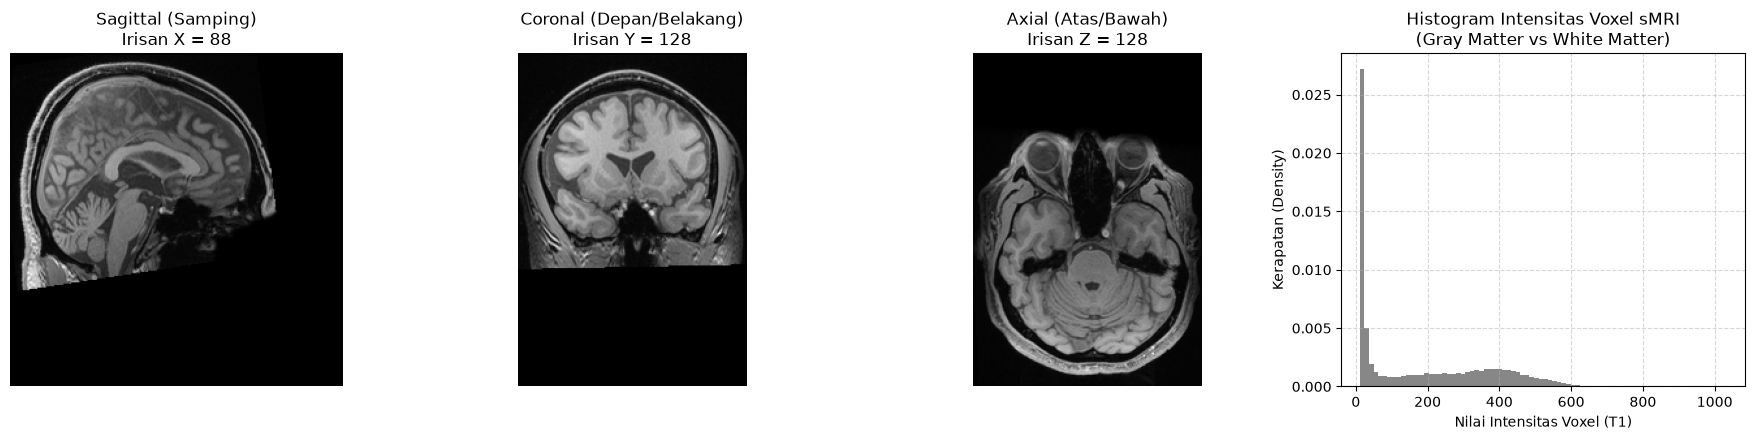

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))

x_mid, y_mid, z_mid = [s // 2 for s in data_smri.shape]

# 1. Sagittal
axs[0].imshow(np.rot90(data_smri[x_mid, :, :]), cmap="gray")
axs[0].set_title(f"Sagittal (Samping)\nIrisan X = {x_mid}")
axs[0].axis("off")

# 2. Coronal
axs[1].imshow(np.rot90(data_smri[:, y_mid, :]), cmap="gray")
axs[1].set_title(f"Coronal (Depan/Belakang)\nIrisan Y = {y_mid}")
axs[1].axis("off")

# 3. Axial
axs[2].imshow(np.rot90(data_smri[:, :, z_mid]), cmap="gray")
axs[2].set_title(f"Axial (Atas/Bawah)\nIrisan Z = {z_mid}")
axs[2].axis("off")

# 4. Histogram Distribusi Intensitas Voxel
voxel_nonzero = data_smri[data_smri > 10].flatten() # Hilangkan udara di luar kepala (>10)
axs[3].hist(voxel_nonzero, bins=80, color="dimgray", density=True, alpha=0.8)
axs[3].set_title("Histogram Intensitas Voxel sMRI\n(Gray Matter vs White Matter)")
axs[3].set_xlabel("Nilai Intensitas Voxel (T1)")
axs[3].set_ylabel("Kerapatan (Density)")
axs[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
simpan_gambar(fig, "smri_eksplorasi_mendalam_caltech")
plt.show()

## 3. Eksplorasi Mendalam rs-fMRI 4D: Dinamika Waktu, Sinyal BOLD & Global Signal Drift

fMRI merekam fluktuasi hemodinamik (kadar oksigen darah / BOLD). Di bawah ini kita melihat rekaman satu irisan axial terhadap waktu dan grafik sinyal BOLD pada 1 voxel di tengah otak, serta sinyal rata-rata seluruh otak (*Global Signal*).

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\fmri_sinyal_dan_global_drift_caltech.png


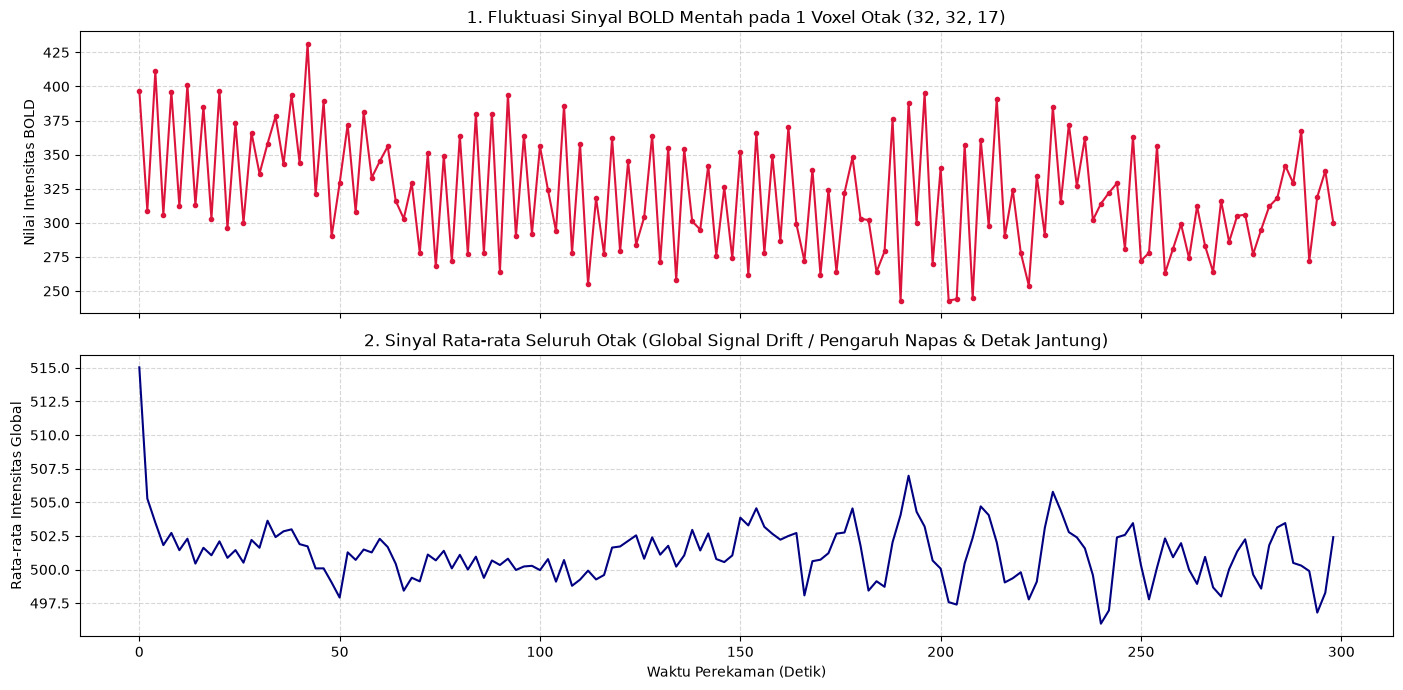

Fluktuasi Sinyal 1 Voxel: Min = 243.0, Max = 431.0, Standar Deviasi = 43.0
Fluktuasi Global Signal : Min = 496.0, Max = 515.0, Standar Deviasi = 2.2


In [4]:
# 1. Ambil sinyal 1 voxel di tengah otak (32, 32, 17) sepanjang 150 volume
voxel_ts = data_fmri[32, 32, 17, :]

# 2. Hitung Sinyal Rata-rata Seluruh Otak (Global Signal) pada tiap detik
# Masking sederhana untuk voxel otak (intensitas > 100)
brain_mask = data_fmri.mean(axis=-1) > 100
global_signal = data_fmri[brain_mask].mean(axis=0)

tr = fmri_img.header.get_zooms()[3]
waktu_detik = np.arange(len(voxel_ts)) * tr

fig, axs = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Plot 1: Sinyal 1 Voxel Spesifik
axs[0].plot(waktu_detik, voxel_ts, color="crimson", lw=1.5, marker="o", markersize=3)
axs[0].set_title("1. Fluktuasi Sinyal BOLD Mentah pada 1 Voxel Otak (32, 32, 17)")
axs[0].set_ylabel("Nilai Intensitas BOLD")
axs[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Sinyal Rata-rata Seluruh Otak (Global Signal)
axs[1].plot(waktu_detik, global_signal, color="navy", lw=1.5)
axs[1].set_title("2. Sinyal Rata-rata Seluruh Otak (Global Signal Drift / Pengaruh Napas & Detak Jantung)")
axs[1].set_xlabel("Waktu Perekaman (Detik)")
axs[1].set_ylabel("Rata-rata Intensitas Global")
axs[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
simpan_gambar(fig, "fmri_sinyal_dan_global_drift_caltech")
plt.show()

print(f"Fluktuasi Sinyal 1 Voxel: Min = {voxel_ts.min():.1f}, Max = {voxel_ts.max():.1f}, Standar Deviasi = {voxel_ts.std():.1f}")
print(f"Fluktuasi Global Signal : Min = {global_signal.min():.1f}, Max = {global_signal.max():.1f}, Standar Deviasi = {global_signal.std():.1f}")

## 4. Analisis Heterogenitas Scanner Multi-Situs pada Data Raw

Setiap institusi di ABIDE I menggunakan mesin MRI dan konfigurasi protokol yang berbeda. Tabel dan grafik di bawah ini membandingkan parameter teknis citra mentah dari 4 situs berbeda (**Caltech**, **KKI**, **NYU**, **Stanford**):

In [5]:
situs_sampel = [
    ("Caltech", "0051456"),
    ("KKI", "0050772"),
    ("NYU", "0050952"),
    ("Stanford", "0050727")
]

hasil_perbandingan = []

for situs, sub_id in situs_sampel:
    p_smri = RAW_DIR / situs / sub_id / "session_1" / "anat_1" / "mprage.nii.gz"
    p_fmri = RAW_DIR / situs / sub_id / "session_1" / "rest_1" / "rest.nii.gz"
    
    if p_smri.exists() and p_fmri.exists():
        s_img = nib.load(p_smri)
        f_img = nib.load(p_fmri)
        
        s_shape = s_img.shape
        s_vox = np.round(s_img.header.get_zooms()[:3], 2)
        
        f_shape = f_img.shape
        f_vox = np.round(f_img.header.get_zooms()[:3], 2)
        f_tr = f_img.header.get_zooms()[3]
        f_timepoints = f_shape[-1]
        
        hasil_perbandingan.append({
            "Situs": situs,
            "SUB_ID": sub_id,
            "Grid sMRI (3D)": f"{s_shape[0]}x{s_shape[1]}x{s_shape[2]}",
            "Voxel sMRI (mm)": f"{s_vox[0]}x{s_vox[1]}x{s_vox[2]}",
            "Grid fMRI (4D)": f"{f_shape[0]}x{f_shape[1]}x{f_shape[2]}x{f_timepoints}",
            "Voxel fMRI (mm)": f"{f_vox[0]}x{f_vox[1]}x{f_vox[2]}",
            "TR fMRI (detik)": f"{f_tr:.2f} s",
            "Total Titik Waktu": f_timepoints,
            "Durasi Scan (menit)": f"{(f_timepoints * f_tr) / 60:.1f} m"
        })

df_situs_comp = pd.DataFrame(hasil_perbandingan)
print("=== PERBANDINGAN HETEROGENITAS PROTOKOL SCANNER RAW ANTAR-SITUS ===")
display(df_situs_comp)

=== PERBANDINGAN HETEROGENITAS PROTOKOL SCANNER RAW ANTAR-SITUS ===


,Situs,SUB_ID,Grid sMRI (3D),Voxel sMRI (mm),Grid fMRI (4D),Voxel fMRI (mm),TR fMRI (detik),Total Titik Waktu,Durasi Scan (menit)
0,Caltech,0051456,176x256x256,1.0x1.0x1.0,64x64x34x150,3.5x3.5x3.5,2.00 s,150,5.0 m
1,KKI,0050772,256x200x256,1.0x1.0x1.0,96x96x47x156,2.6700000762939453x2.6700000762939453x3.0,2.50 s,156,6.5 m
2,NYU,0050952,128x256x256,1.3300000429153442x1.0x1.0,64x80x33x180,3.0x3.0x4.0,2.00 s,180,6.0 m


## 5. Komparasi Visual Langsung: Pasien ASD vs Kontrol Sehat pada Citra Mentah

Di bawah ini kita membandingkan irisan anatomi sMRI dan dinamika sinyal fMRI antara:
* **Subjek ASD (Caltech 0051456)**
* **Subjek Kontrol / TD (KKI 0050772)**

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\komparasi_raw_asd_vs_kontrol.png


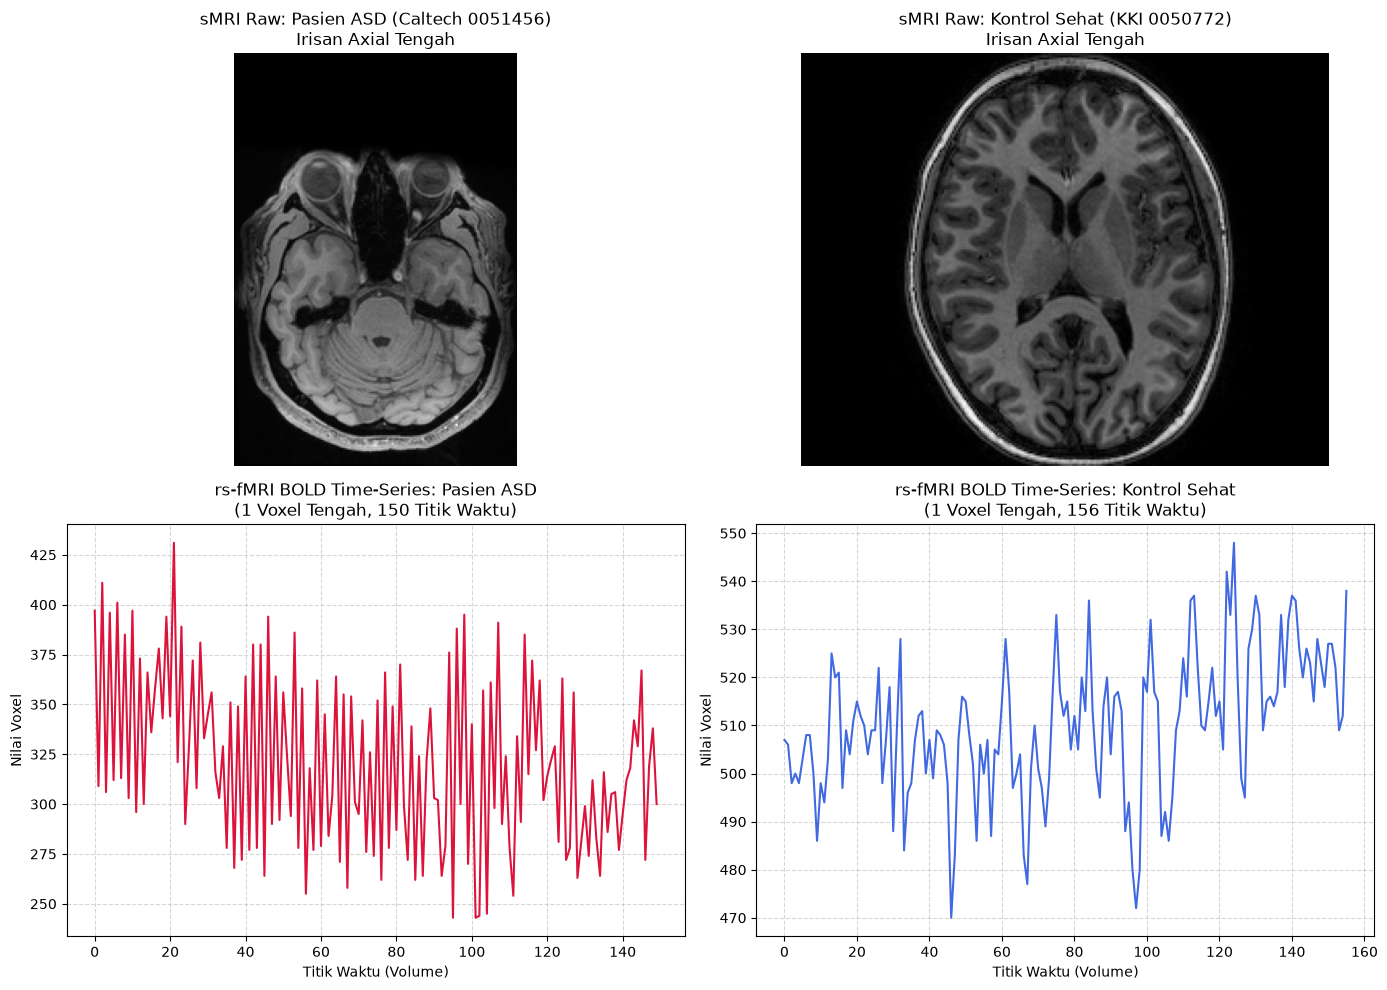

In [6]:
# Load subjek kontrol (KKI 0050772)
kki_smri_path = RAW_DIR / "KKI" / "0050772" / "session_1" / "anat_1" / "mprage.nii.gz"
kki_fmri_path = RAW_DIR / "KKI" / "0050772" / "session_1" / "rest_1" / "rest.nii.gz"

kki_smri_data = nib.load(kki_smri_path).get_fdata()
kki_fmri_data = nib.load(kki_fmri_path).get_fdata()

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1. sMRI ASD (Caltech)
axs[0, 0].imshow(np.rot90(data_smri[:, :, data_smri.shape[2]//2]), cmap="gray")
axs[0, 0].set_title("sMRI Raw: Pasien ASD (Caltech 0051456)\nIrisan Axial Tengah")
axs[0, 0].axis("off")

# 2. sMRI Kontrol (KKI)
axs[0, 1].imshow(np.rot90(kki_smri_data[:, :, kki_smri_data.shape[2]//2]), cmap="gray")
axs[0, 1].set_title("sMRI Raw: Kontrol Sehat (KKI 0050772)\nIrisan Axial Tengah")
axs[0, 1].axis("off")

# 3. fMRI BOLD Time-Series ASD (150 waktu)
t_asd = np.arange(data_fmri.shape[-1])
ts_asd = data_fmri[32, 32, 17, :]
axs[1, 0].plot(ts_asd, color="crimson", lw=1.5)
axs[1, 0].set_title("rs-fMRI BOLD Time-Series: Pasien ASD\n(1 Voxel Tengah, 150 Titik Waktu)")
axs[1, 0].set_xlabel("Titik Waktu (Volume)")
axs[1, 0].set_ylabel("Nilai Voxel")
axs[1, 0].grid(True, linestyle="--", alpha=0.5)

# 4. fMRI BOLD Time-Series Kontrol (156 waktu)
ts_kki = kki_fmri_data[kki_fmri_data.shape[0]//2, kki_fmri_data.shape[1]//2, kki_fmri_data.shape[2]//2, :]
axs[1, 1].plot(ts_kki, color="royalblue", lw=1.5)
axs[1, 1].set_title("rs-fMRI BOLD Time-Series: Kontrol Sehat\n(1 Voxel Tengah, 156 Titik Waktu)")
axs[1, 1].set_xlabel("Titik Waktu (Volume)")
axs[1, 1].set_ylabel("Nilai Voxel")
axs[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
simpan_gambar(fig, "komparasi_raw_asd_vs_kontrol")
plt.show()

## 6. Kesimpulan Penting dari Eksplorasi Citra Mentah (*Raw Data*)

1. **Perbedaan Autisme Tidak Terlihat Kasar Secara Visual**:
   - Struktur sMRI pasien ASD dan orang sehat secara kasat mata **terlihat sama persis** (tidak ada cacat fisik atau lubang pada otak).
   - Perbedaan autisme terletak pada **interaksi konektivitas mikro antar-jaringan saraf** (*functional connectome*), yang hanya bisa dianalisis setelah ekstraksi sinyal korelasi dan pemodelan AI/GNN.
2. **Kebutuhan Standardisasi Preprocessing (PCP)**:
   - Data mentah memiliki **perbedaan dimensi kisi voxel**, **perbedaan durasi waktu (150 vs 180 vs 240 volume)**, serta **noise pernapasan / pergerakan kepala subjek**.
   - Oleh karena itu, pipeline preprocessing terstandarisasi (seperti PCP) sangat penting untuk meratakan orientasi ke atlas standar MNI dan membersihkan fluktuasi noise.